# 2. Tabular Q-Learning: ε-Greedy vs. Boltzmann Exploration

Q-learning learns the optimal action values from experience, without knowing the transition or reward functions. This notebook runs it on the same stochastic maze as notebook 1 and studies how the amount of exploration affects learning.

- **ε-greedy:** with probability ε, take a random action; otherwise take the greedy one.
- **Boltzmann (softmax):** sample actions with probability $\propto \exp(Q(s,a)/\tau)$. A higher temperature τ means more exploration, and τ = 0 is purely greedy.

Each setting is averaged over 100 independent trials. Every episode starts in cell 0 and lasts 100 steps, and rewards are sampled from a unit-variance Gaussian around the maze's reward. The learning rate is $1/n(s,a)$, where $n(s,a)$ counts the visits to each state-action pair. The 100 trials run in parallel as NumPy arrays.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from maze import maze_mdp

mdp = maze_mdp()
V_star, _, _ = mdp.value_iteration(tolerance=1e-6)
optimal_policy = mdp.extract_policy(V_star)
DECISION_STATES = np.array([s for s in range(16) if s != 14])

TRIALS, EPISODES, STEPS = 100, 2000, 100
PLOT_EPISODES = 200

## Q-learning

In [2]:
def q_learning(mdp, epsilon=0.0, temperature=0.0, trials=TRIALS, episodes=EPISODES, steps=STEPS,
               start_state=0, snapshot_episode=PLOT_EPISODES, seed=0):
    rng = np.random.default_rng(seed)
    n_actions, n_states = mdp.nActions, mdp.nStates
    cumulative_T = np.cumsum(mdp.T, axis=2)
    trial = np.arange(trials)

    Q = np.zeros((trials, n_actions, n_states))
    visits = np.zeros_like(Q)
    discounted_returns = np.zeros((trials, episodes))
    snapshot = None

    for episode in range(episodes):
        state = np.full(trials, start_state)
        for step in range(steps):
            q = Q[trial, :, state]
            if epsilon > 0:
                action = np.where(rng.random(trials) < epsilon,
                                  rng.integers(n_actions, size=trials), q.argmax(axis=1))
            elif temperature > 0:
                logits = (q - q.max(axis=1, keepdims=True)) / temperature
                probs = np.exp(logits) / np.exp(logits).sum(axis=1, keepdims=True)
                action = (rng.random((trials, 1)) < probs.cumsum(axis=1)).argmax(axis=1)
            else:
                action = q.argmax(axis=1)

            reward = rng.normal(mdp.R[action, state])
            next_state = (rng.random((trials, 1)) < cumulative_T[action, state]).argmax(axis=1)

            visits[trial, action, state] += 1
            alpha = 1.0 / visits[trial, action, state]
            target = reward + mdp.discount * Q[trial, :, next_state].max(axis=1)
            Q[trial, action, state] += alpha * (target - Q[trial, action, state])

            discounted_returns[:, episode] += mdp.discount ** step * reward
            state = next_state

        if episode + 1 == snapshot_episode:
            snapshot = Q.copy()

    return Q, snapshot, discounted_returns


def policy_agreement(Q):
    greedy = Q.argmax(axis=1)
    return (greedy[:, DECISION_STATES] == optimal_policy[DECISION_STATES]).mean()


def value_error(Q):
    return np.abs(Q.max(axis=1)[:, :16] - V_star[:16]).mean()

## Run all exploration settings

In [3]:
settings = {
    "ε = 0.1": dict(epsilon=0.1),
    "ε = 0.3": dict(epsilon=0.3),
    "ε = 0.5": dict(epsilon=0.5),
    "τ = 0 (greedy)": dict(temperature=0.0),
    "τ = 10": dict(temperature=10.0),
    "τ = 20": dict(temperature=20.0),
}

results, rows = {}, []
for i, (name, kwargs) in enumerate(settings.items()):
    Q, Q_200, returns = q_learning(mdp, seed=i, **kwargs)
    results[name] = returns
    rows.append({
        "Setting": name,
        "Avg. return, episodes 1–200": returns[:, :PLOT_EPISODES].mean().round(1),
        "Optimal actions after 200 ep.": f"{policy_agreement(Q_200):.0%}",
        "Optimal actions after 2000 ep.": f"{policy_agreement(Q):.0%}",
        "Mean |max Q − V*| after 2000 ep.": value_error(Q).round(2),
    })

summary = pd.DataFrame(rows).set_index("Setting")
summary

,"Avg. return, episodes 1–200",Optimal actions after 200 ep.,Optimal actions after 2000 ep.,Mean |max Q − V*| after 2000 ep.
Setting,,,,
ε = 0.1,30.4,62%,69%,14.84
ε = 0.3,22.0,64%,72%,10.03
ε = 0.5,8.9,68%,74%,8.41
τ = 0 (greedy),24.2,53%,53%,31.12
τ = 10,26.0,69%,75%,11.85
τ = 20,12.8,72%,75%,8.28


"Optimal actions" is the share of the 15 decision cells (all except the goal) where the learned greedy action matches the optimal policy from value iteration, averaged over the 100 trials.

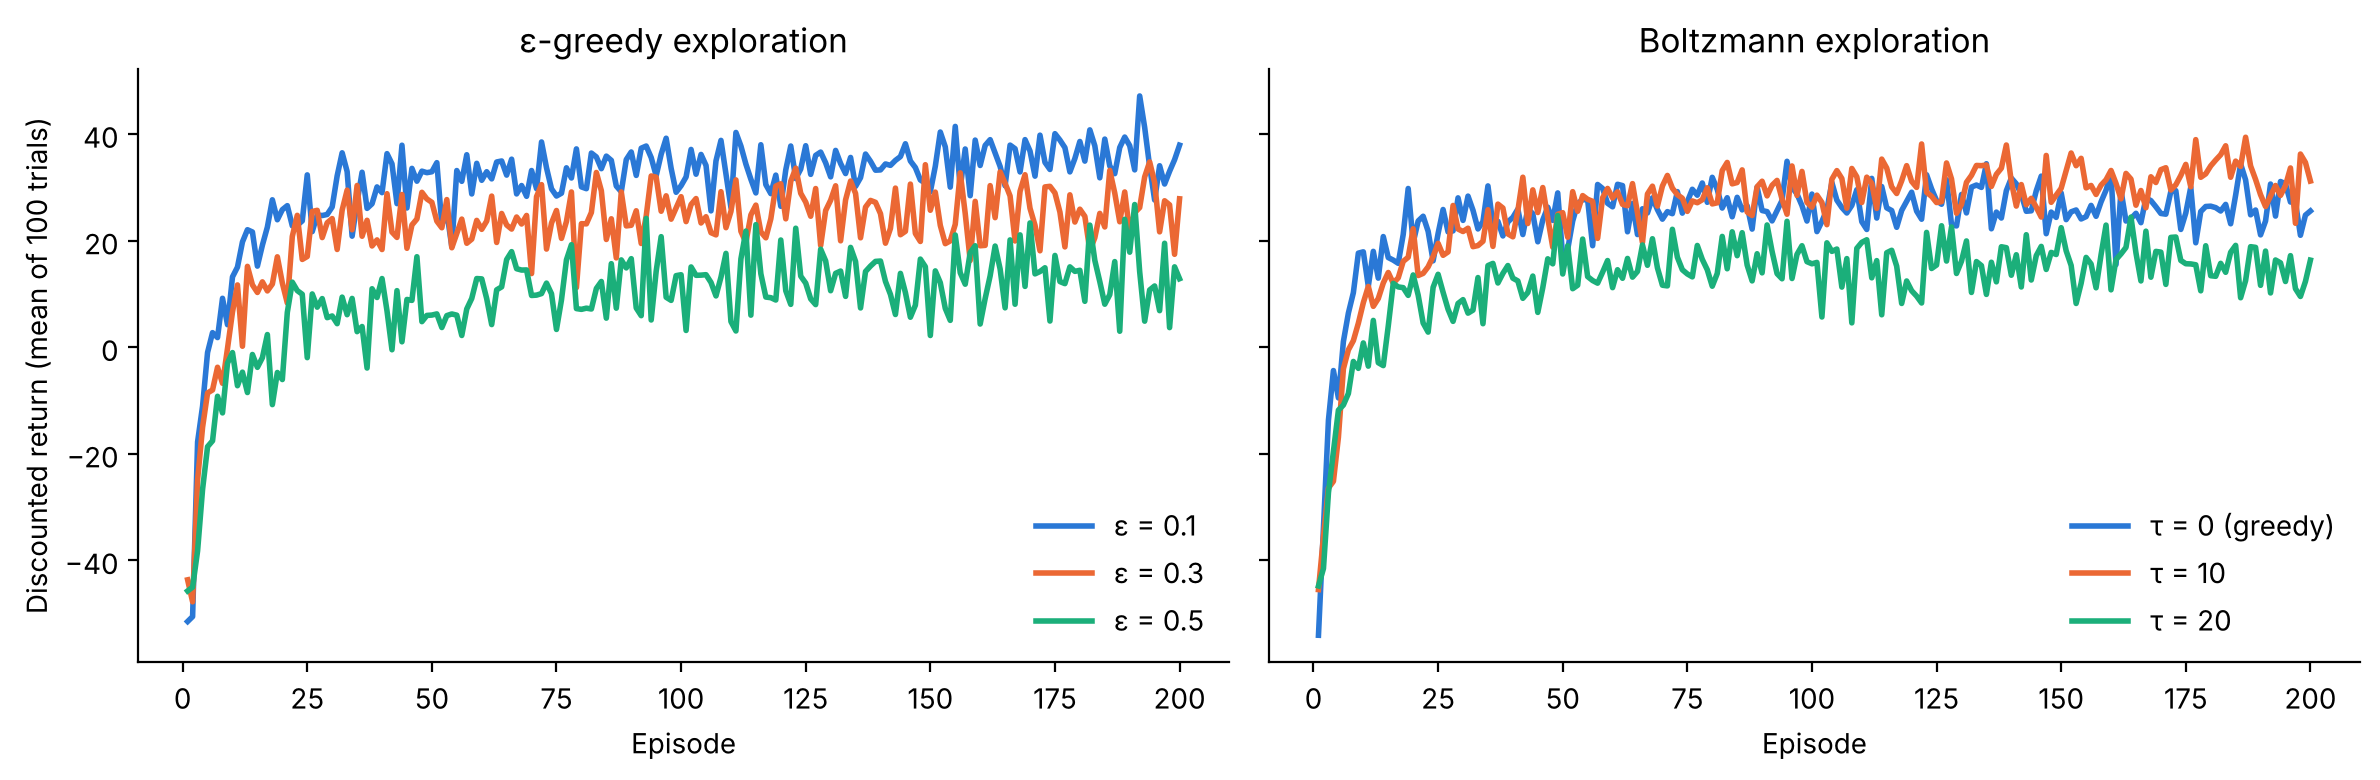

In [4]:
colors = ["#2a78d6", "#eb6834", "#1baf7a"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, names, title in [(axes[0], list(settings)[:3], "ε-greedy exploration"),
                         (axes[1], list(settings)[3:], "Boltzmann exploration")]:
    for name, color in zip(names, colors):
        ax.plot(range(1, PLOT_EPISODES + 1), results[name][:, :PLOT_EPISODES].mean(axis=0),
                color=color, lw=2, label=name)
    ax.set_title(title)
    ax.set_xlabel("Episode")
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, loc="lower right")
axes[0].set_ylabel("Discounted return (mean of 100 trials)")
plt.tight_layout()
plt.savefig("figures/q_learning_exploration.png", dpi=150)
plt.show()